In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm

def trotter_Tmax(psi0, Ht, N, Tmax):
    """
   Brute force trotter evolution up to Tmax with N steps.

    Parameters
    ----------
    psi0 : ndarray, shape (2,)
        Initial state vector.
    Ht : callable
        Function Ht(t) returning a 2x2 Hamiltonian at time t.
    N : int
        Number of time steps.
    Tmax : float
        Maximum evolution time.

    Returns
    -------
    psipsif : ndarray, shape (2, N)
        State vector at each timestep.
    """

    dt = Tmax / N
    psipsi = np.zeros((2, N), dtype=complex)

    for k in range(1, N+1):
        H = Ht((k-1) * dt)
        Udt = expm(-1j * H * dt)
        psi0 = Udt @ psi0
        psipsi[:, k-1] = psi0

    return psipsi

In [2]:
# Pauli matrices (can be reused by all Hamiltonians)
X = np.array([[0, 1], [1, 0]], dtype=complex)
Y = np.array([[0, -1j], [1j, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)

def rotating_magnetic_field(t, omegaL, nvec, omegad, Omega):
    Hstat = 0.5 * omegaL * (nvec[0]*X + nvec[1]*Y + nvec[2]*Z)
    Hd = 0.5 * Omega * (np.cos(omegad * t) * X + np.sin(omegad * t) * Y)
    return Hstat + Hd

def linear_magnetic_field(t, omegaL, nvec, omegad, Omega):
    Hstat = 0.5 * omegaL * (nvec[0]*X + nvec[1]*Y + nvec[2]*Z)
    Hd = 0.5 * Omega * np.cos(omegad * t) * X
    return Hstat + Hd

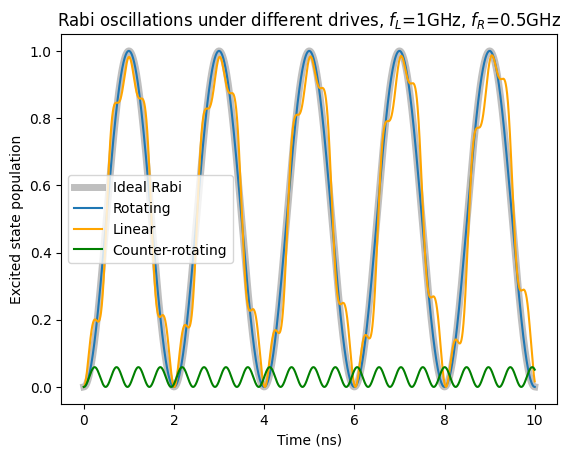

In [3]:
psi0 = np.array([1.0, 0], dtype=complex) # initial state
nvec = np.array([0, 0, 1])  # z-axis

Drive = 0.5 * 2 * np.pi  # Rabi frequency = 0.5 GHz
Tfinal = 2*np.pi/Drive * 5  # 5 Rabi cycles
Nsteps = 5000

omegaL = 1.0 * 2 * np.pi  # Larmor frequency = 1 GHz

Hrot = lambda t: rotating_magnetic_field(t, omegaL=omegaL, nvec=nvec, omegad=omegaL, Omega=Drive)


res = trotter_Tmax(psi0, Hrot, N=Nsteps, Tmax=Tfinal)

Hlinear = lambda t: linear_magnetic_field(t, omegaL=omegaL, nvec=nvec, omegad=omegaL, Omega=Drive*2)

res_lin = trotter_Tmax(psi0, Hlinear, Nsteps, Tfinal)

Hcounter = lambda t: rotating_magnetic_field(t, omegaL=omegaL, nvec=nvec, omegad=-omegaL, Omega=Drive)

res_counter = trotter_Tmax(psi0, Hcounter, Nsteps, Tfinal)

tt = np.linspace(0, Tfinal, Nsteps)
plt.plot(tt, np.sin(Drive/2 * tt)**2, linewidth=5, color='gray', alpha=0.5)
plt.plot(tt, np.square(np.abs(res[1, :])))
plt.plot(tt, np.square(np.abs(res_lin[1, :])), color = 'orange')
plt.plot(tt, np.square(np.abs(res_counter[1, :])), color='green')
plt.xlabel('Time (ns)')
plt.ylabel('Excited state population')
plt.legend(['Ideal Rabi', 'Rotating', 'Linear', 'Counter-rotating'])
plt.title('Rabi oscillations under different drives, $f_L$=1GHz, $f_R$=0.5GHz')
plt.show()

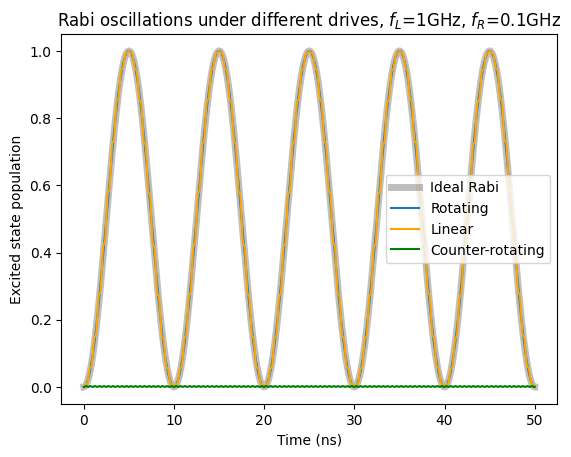

In [4]:
Drive = 0.1 * 2 * np.pi  # Rabi frequency = 0.1 GHz
Tfinal = 2*np.pi/Drive * 5  # 5 Rabi cycles

Hrot = lambda t: rotating_magnetic_field(t, omegaL=omegaL, nvec=nvec, omegad=omegaL, Omega=Drive)

res = trotter_Tmax(psi0, Hrot, N=Nsteps, Tmax=Tfinal)

Hlinear = lambda t: linear_magnetic_field(t, omegaL=omegaL, nvec=nvec, omegad=omegaL, Omega=Drive*2)

res_lin = trotter_Tmax(psi0, Hlinear, Nsteps, Tfinal)

Hcounter = lambda t: rotating_magnetic_field(t, omegaL=omegaL, nvec=nvec, omegad=-omegaL, Omega=Drive)

res_counter = trotter_Tmax(psi0, Hcounter, Nsteps, Tfinal)

tt = np.linspace(0, Tfinal, Nsteps)
plt.plot(tt, np.sin(Drive/2 * tt)**2, linewidth=5, color='gray', alpha=0.5)
plt.plot(tt, np.square(np.abs(res[1, :])))
plt.plot(tt, np.square(np.abs(res_lin[1, :])), color = 'orange')
plt.plot(tt, np.square(np.abs(res_counter[1, :])), color='green')
plt.xlabel('Time (ns)')
plt.ylabel('Excited state population')
plt.legend(['Ideal Rabi', 'Rotating', 'Linear', 'Counter-rotating'])
plt.title('Rabi oscillations under different drives, $f_L$=1GHz, $f_R$=0.1GHz')
plt.show()
